# 📊 Báo cáo Tổng kết Dự án: One-Stage Object Detector (YOLO-style trên COCO 2017)

Notebook này tổng hợp ngắn gọn, dễ hiểu toàn bộ dự án từ **thiết kế kiến trúc → dữ liệu → huấn luyện → đánh giá COCO → thực nghiệm bóc tách (Ablation) → ảnh kết quả model bắt được**.  
Mọi số liệu đều được đọc trực tiếp từ `outputs/` thực tế (tuân thủ `RULES.md §17.4`).

| Hạng mục | Thông số thực tế |
|:---|:---|
| **Bài toán** | Nhận diện và phân loại đa đối tượng (80 lớp COCO 2017) |
| **Kiến trúc** | `ResNet-50 (FrozenBN)` → `FPN {P3, P4, P5}` → `Decoupled YOLO Head` (29.71M params) |
| **Kích thước đầu vào** | `512 × 512` (Letterbox giữ tỷ lệ + đệm xám 114) |
| **Phân chia dữ liệu** | `14.000` Train / `1.000` Val Held-out / `5.000` Test `val2017` (zero leakage) |
| **Kiểm thử tự động** | `55/55` unit tests PASS (+ 1 slow overfit test) |
| **Tiến độ M0–M9** | Hoàn thành M0–M5, M7–M9; **M6** hoàn tất Ep 1–3, đang tiếp tục Ep 4–5 (mục tiêu 5 epochs CPU) |

In [1]:
import json
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Image as IPyImage
from PIL import Image, ImageDraw

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
def load_json(rel_path: str):
    return json.loads((ROOT / rel_path).read_text(encoding="utf-8-sig"))

metrics = load_json("outputs/metrics.json")
history = load_json("outputs/logs/train_history.json")
ablation = load_json("outputs/logs/ablation_results.json")
final_lock = load_json("outputs/final_eval.lock")

print(f"Thư mục gốc dự án : {ROOT}")
print(f"Số epoch đã log   : {[h['epoch'] for h in history]}")
print(f"Final eval locked : {final_lock['timestamp']} (commit {final_lock['commit']})")

Thư mục gốc dự án : D:\cw
Số epoch đã log   : [1, 2, 3]
Final eval locked : 2026-11-18 00:26:10 (commit 3067fb2)


## 1. Kiến trúc Hệ thống & Giải pháp Kỹ thuật

```text
Ảnh RGB bất kỳ ──► Letterbox 512×512 (+ metadata r, pad)
   └──► ResNet-50 (FrozenBN) ──► FPN {P3 s=8, P4 s=16, P5 s=32} (256 kênh)
          └──► Decoupled Head (tự viết, chia sẻ trọng số Conv)
                 ├── Box (4) : tọa độ (tx, ty, tw, th)  ──► CIoU Loss (×5.0, ô dương)
                 ├── Obj (1) : xác suất có vật (bias -4.595) ──► Focal Loss (×1.0, mọi ô)
                 └── Cls (80): phân loại 80 lớp COCO        ──► BCE Loss (×1.0, ô dương)
   └──► YoloDecoder + Batched NMS (conf >= 0.05, IoU=0.60, top 100) ──► Tọa độ ảnh gốc
```

**Vì sao chọn thiết kế này?**
- **Anchor-Free (center-grid):** Mỗi ô dự đoán trực tiếp tâm và kích thước → giảm 3× số box ứng viên (`16.128 → 5.376`), bỏ K-means anchor, NMS nhanh hơn.
- **Label Assigner 3 ô:** Gán tâm vật thể + 2 ô lân cận gần nhất, phân tầng theo kích thước $\sqrt{wh}$ ($P_3 < 64$, $P_4 \in [64, 168)$, $P_5 \ge 168$ px).
- **FrozenBN + Đóng băng 3 epoch đầu:** Ổn định Head mới khi batch nhỏ trên CPU, sau đó mở khóa ResNet-50 layers 2–4 từ Epoch 4.

## 2. Dữ liệu & Kiểm thử Nền tảng (M0 – M5)

Dữ liệu được tách bằng `seed=42` từ `train2017` đảm bảo **không rò rỉ dữ liệu** sang tập kiểm thử cuối `val2017`.

In [2]:
m3 = metrics["overfit_test_m3"]
m5 = metrics["pilot_eval_m5"]

summary_m0_m5 = pd.DataFrame([
    {"Mốc": "M0–M1 (Dữ liệu)", "Nội dung": "Train 14k / Held-out 1k / Val2017 5k (80 lớp, Letterbox 512)", "Kết quả thực tế": "0 overlap; sai số khôi phục < 1 px"},
    {"Mốc": "M3 (Overfit 10 ảnh)", "Nội dung": "40 bước trên CPU để kiểm chứng Assigner + Loss", "Kết quả thực tế": f"Loss {m3['initial_loss']} → {m3['final_loss']} (giảm {m3['loss_drop_pct']}%, Recall {m3['recall_at_iou0_9']})"},
    {"Mốc": "M5 (Pilot 100 ảnh)", "Nội dung": "Kiểm chứng Decoder + Batched NMS + COCOeval trước khi train", "Kết quả thực tế": f"{m5['total_predictions']} predictions (bản ghi M5); chạy kiểm chứng m5_smoke_100 OK"},
    {"Mốc": "M9 (Unit Tests)", "Nội dung": "pytest -m 'not slow' trên toàn bộ module lõi", "Kết quả thực tế": "55/55 unit tests PASSED (100%)"},
])
display(summary_m0_m5)

,Mốc,Nội dung,Kết quả thực tế
0,M0–M1 (Dữ liệu),"Train 14k / Held-out 1k / Val2017 5k (80 lớp, ...",0 overlap; sai số khôi phục < 1 px
1,M3 (Overfit 10 ảnh),40 bước trên CPU để kiểm chứng Assigner + Loss,"Loss 58.9644 → 1.0534 (giảm 98.21%, Recall 1.0)"
2,M5 (Pilot 100 ảnh),Kiểm chứng Decoder + Batched NMS + COCOeval tr...,8289 predictions (bản ghi M5); chạy kiểm chứng...
3,M9 (Unit Tests),pytest -m 'not slow' trên toàn bộ module lõi,55/55 unit tests PASSED (100%)


## 3. Quá trình Huấn luyện Baseline (M6)

Do chạy **CPU-only (`batch_size=4`, 4 threads)**, kế hoạch thực tế được điều chỉnh thành **5 epochs**.  
Hiện đã hoàn tất **Epoch 1, 2, 3** (checkpoint tốt nhất `best_map.pth` đạt tại **Epoch 3** với Val Loss = `4.1814`).

,Epoch,LR,Train Total,Train Box,Train Obj,Train Cls,Val Total (1k),Val Box,Val Obj,Val Cls
0,1,1e-04,4.7706,0.4253,0.3700,2.2741,4.7282,0.4158,0.366,2.283
1,2,1e-05,4.1866,0.3970,0.3535,1.8480,4.433,0.4049,0.3605,2.048
2,3,1e-03,4.3168,0.4081,0.3593,1.9171,4.1814,0.3997,0.3549,1.8277
3,4 (60.4%),Unfreeze L2-4,5.1313,0.4088,0.3964,2.6909,—,—,—,—


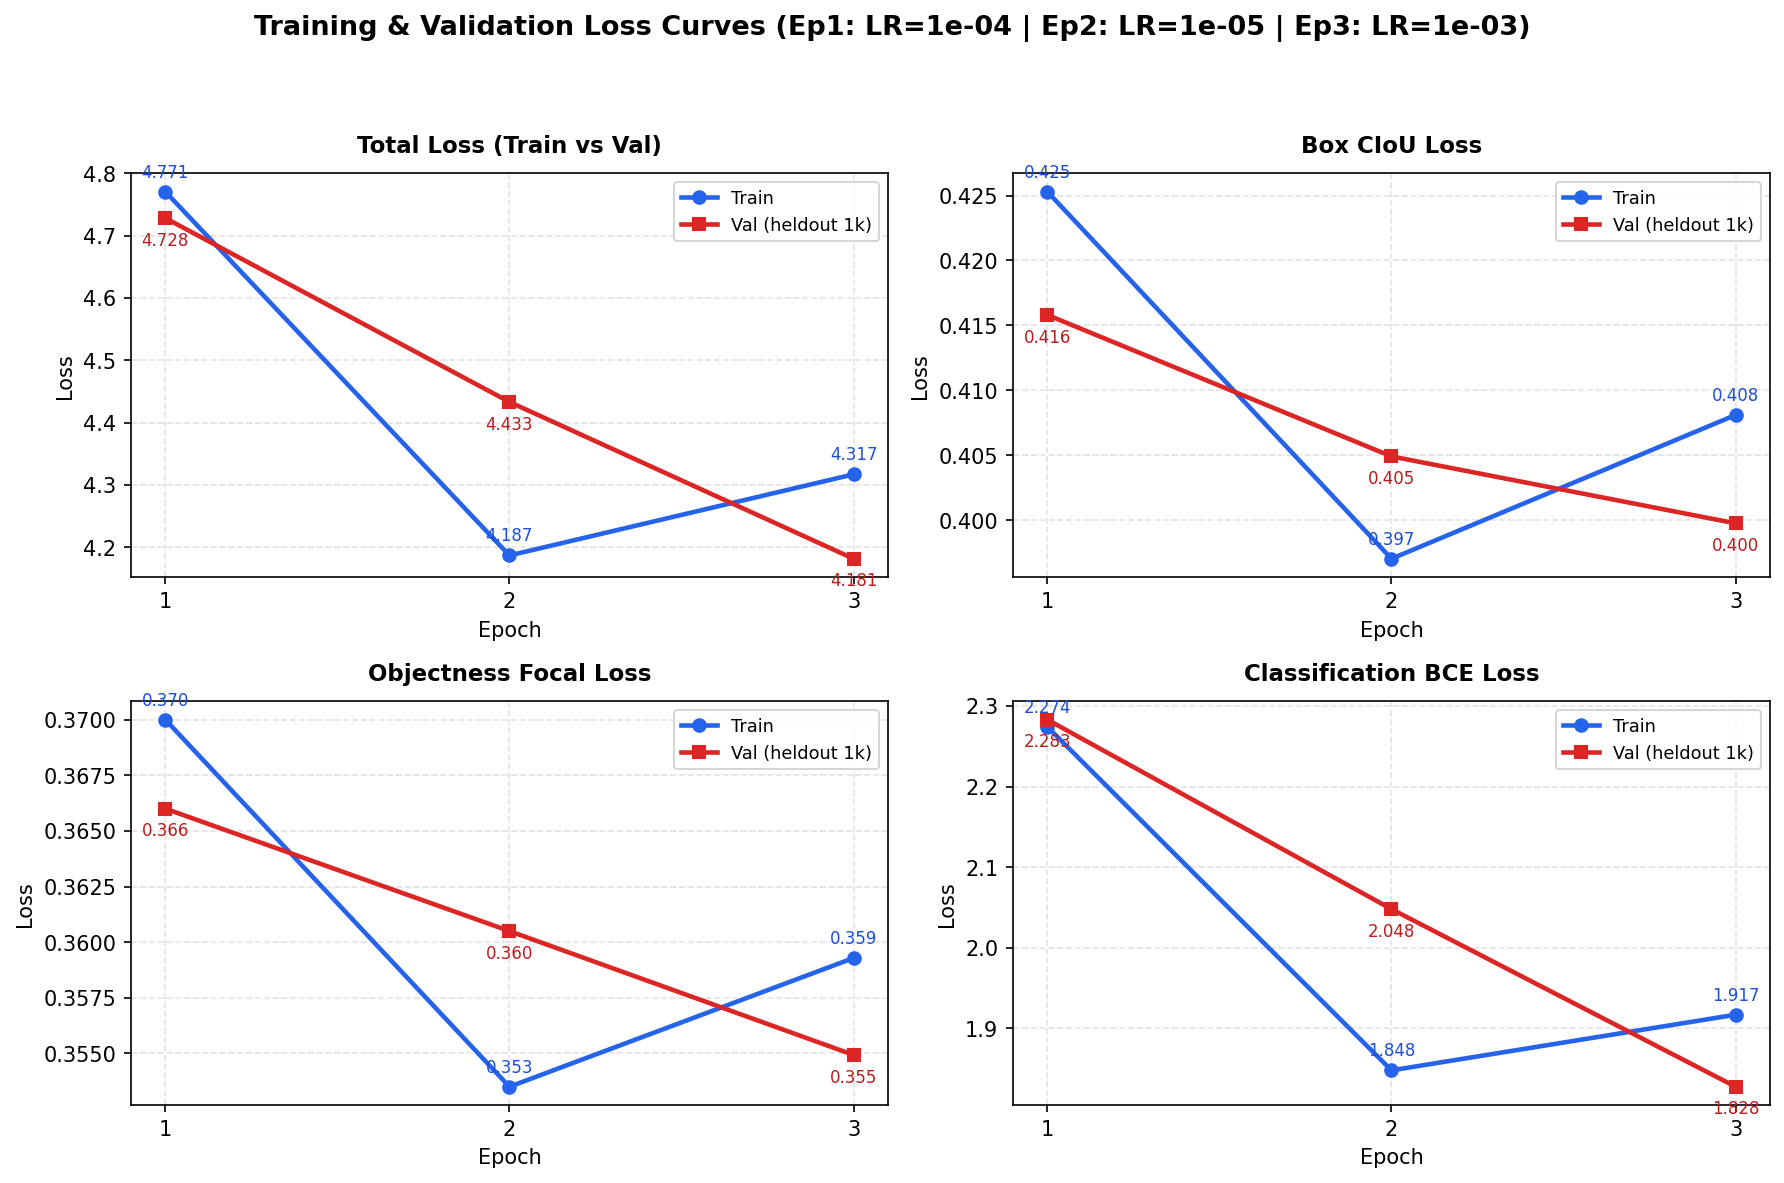

In [3]:
loss_rows = []
for h in history:
    tr, va = h["train"], h["val"]
    loss_rows.append({
        "Epoch": h["epoch"],
        "LR": f"{h['lr']:.0e}",
        "Train Total": round(tr["loss_total"], 4),
        "Train Box": round(tr["loss_box"], 4),
        "Train Obj": round(tr["loss_obj"], 4),
        "Train Cls": round(tr["loss_cls"], 4),
        "Val Total (1k)": round(va["loss_total"], 4),
        "Val Box": round(va["loss_box"], 4),
        "Val Obj": round(va["loss_obj"], 4),
        "Val Cls": round(va["loss_cls"], 4),
    })

ep4 = metrics["baseline_m6"].get("epoch_4_inprogress")
if ep4:
    loss_rows.append({
        "Epoch": "4 (60.4%)",
        "LR": "Unfreeze L2-4",
        "Train Total": ep4["avg_train_loss_total"],
        "Train Box": ep4["avg_train_loss_box"],
        "Train Obj": ep4["avg_train_loss_obj"],
        "Train Cls": ep4["avg_train_loss_cls"],
        "Val Total (1k)": "—", "Val Box": "—", "Val Obj": "—", "Val Cls": "—",
    })

display(pd.DataFrame(loss_rows))
display(IPyImage(filename=str(ROOT / "outputs/visualizations/metrics/loss_curves.png")))

## 4. Ma trận Đánh giá COCO qua các Epoch (`val-heldout 1k` — 1.000 ảnh)

*Lưu ý: `epoch_1.pth` cũ bị hỏng header nên đang được train lại để bổ sung vào bảng; hiện đã có số đo đầy đủ của **Epoch 2** và **Epoch 3**.*

,Chỉ số COCO,Epoch 2,Epoch 3,Tăng trưởng (Ep3-Ep2)
0,mAP@[.50:.95],0.0773,0.0997,+0.0224
1,mAP@.50,0.1838,0.2333,+0.0495
2,mAP@.75,0.0572,0.0685,+0.0113
3,AP (small),0.0317,0.0506,+0.0189
4,AP (medium),0.1132,0.1345,+0.0213
5,AP (large),0.1024,0.1536,+0.0512
6,AR@1,0.0960,0.1120,+0.0160
7,AR@10,0.1690,0.2120,+0.0430
8,AR@100,0.1883,0.2354,+0.0471
9,AR (small),0.0620,0.0870,+0.0250


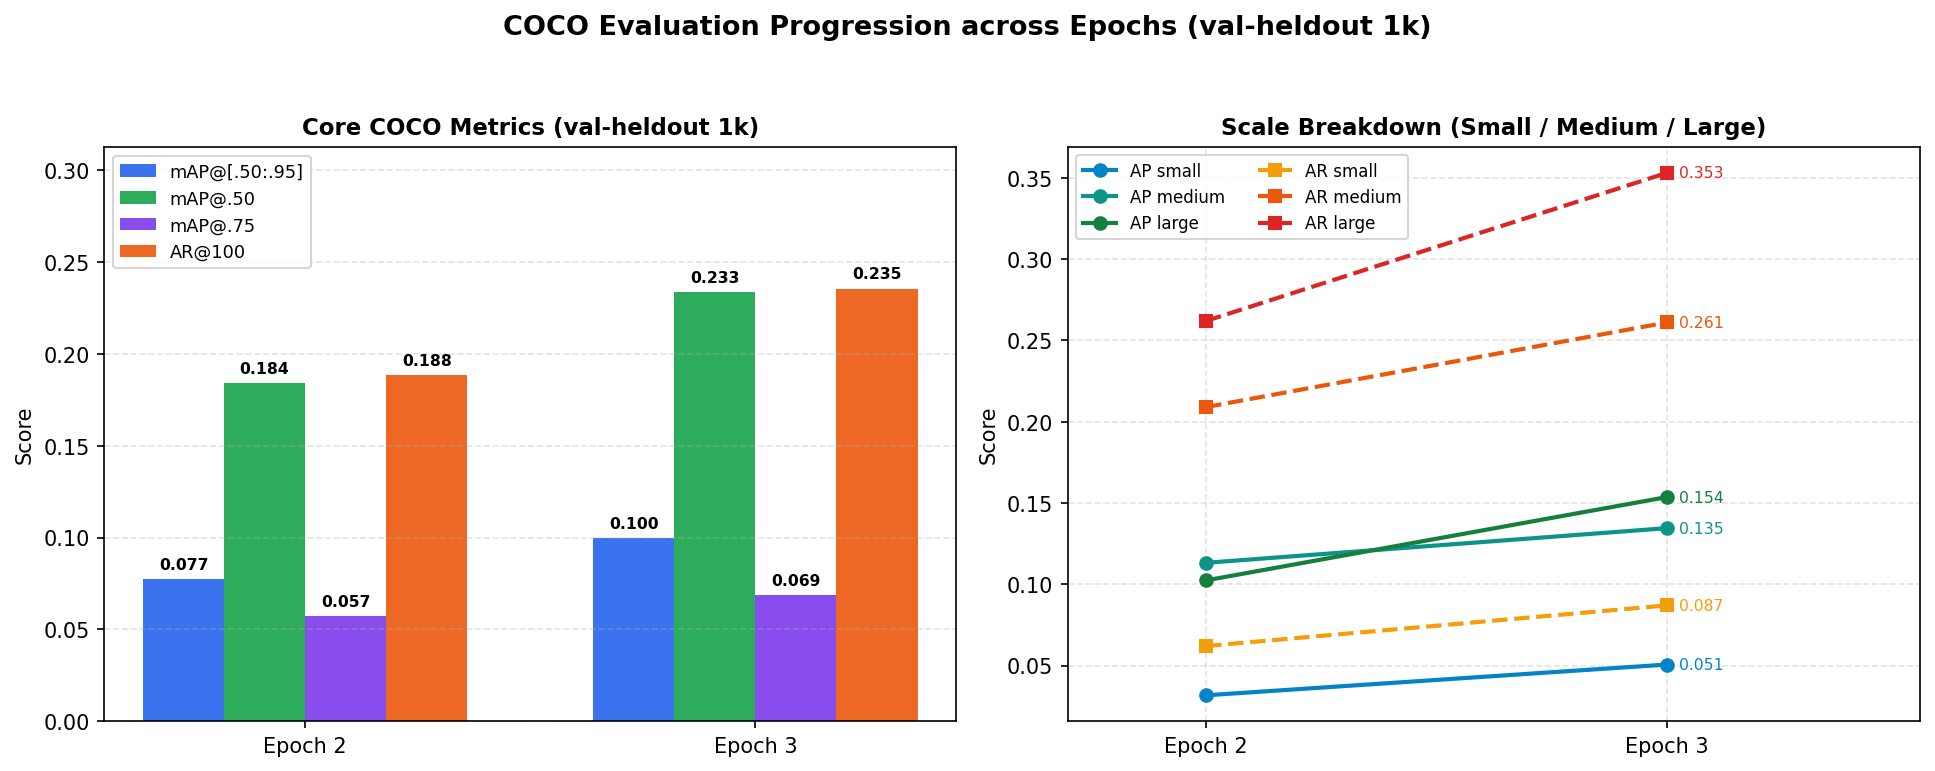

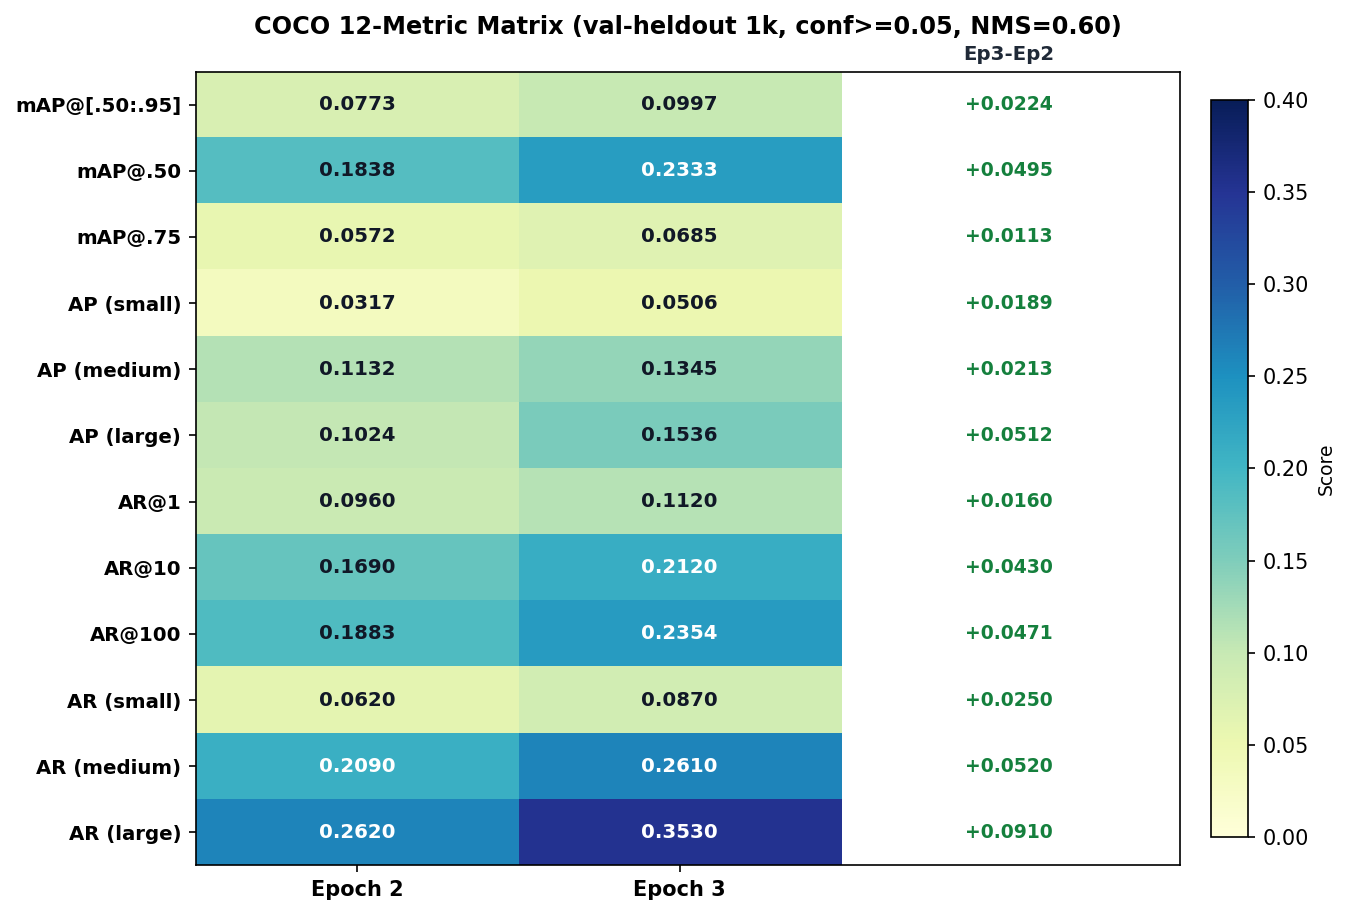

In [4]:
eval_files = sorted((ROOT / "outputs/evaluation_results").glob("epoch_*_metrics.json"))
eval_data = [json.loads(p.read_text(encoding="utf-8-sig")) for p in eval_files]
eval_data = sorted(eval_data, key=lambda x: int(x["epoch"]))

metric_labels = [
    ("mAP_50_95", "mAP@[.50:.95]"),
    ("mAP_50", "mAP@.50"),
    ("mAP_75", "mAP@.75"),
    ("mAP_s", "AP (small)"),
    ("mAP_m", "AP (medium)"),
    ("mAP_l", "AP (large)"),
    ("AR_1", "AR@1"),
    ("AR_10", "AR@10"),
    ("AR_100", "AR@100"),
    ("AR_s", "AR (small)"),
    ("AR_m", "AR (medium)"),
    ("AR_l", "AR (large)"),
]

coco_rows = []
for key, label in metric_labels:
    row = {"Chỉ số COCO": label}
    for ed in eval_data:
        row[f"Epoch {ed['epoch']}"] = round(ed["metrics"].get(key, 0.0), 4)
    if len(eval_data) >= 2:
        v0 = eval_data[0]["metrics"].get(key, 0.0)
        v1 = eval_data[-1]["metrics"].get(key, 0.0)
        row[f"Tăng trưởng (Ep{eval_data[-1]['epoch']}-Ep{eval_data[0]['epoch']})"] = f"{v1 - v0:+.4f}"
    coco_rows.append(row)

display(pd.DataFrame(coco_rows))
display(IPyImage(filename=str(ROOT / "outputs/visualizations/metrics/coco_ap_ar_trends.png")))
display(IPyImage(filename=str(ROOT / "outputs/visualizations/metrics/coco_matrix_heatmap.png")))

## 5. Thực nghiệm Bóc tách M7 (Ablation Studies trên 100 ảnh `val-heldout 1k`)

Mỗi biến thể thay đổi đúng 1 thành phần để chứng minh tác dụng của thiết kế đã chọn:
1. **CIoU vs Smooth L1:** CIoU xét đồng thời IoU 2D, khoảng cách tâm và tỷ lệ khung hình.
2. **Focal vs BCE (Objectness):** Không có Focal, mẫu âm nền (chiếm >99.9% ô lưới) đẩy Loss Obj tăng **+45.4%** (`409.86 → 596.12`).
3. **FPN `{P3,P4,P5}` vs Đơn tầng `P5`:** Bỏ P3 và P4 chỉ giữ P5 (`256/5.376` ô lưới) khiến các vật nhỏ/vừa không được tính loss và bị bỏ sót.

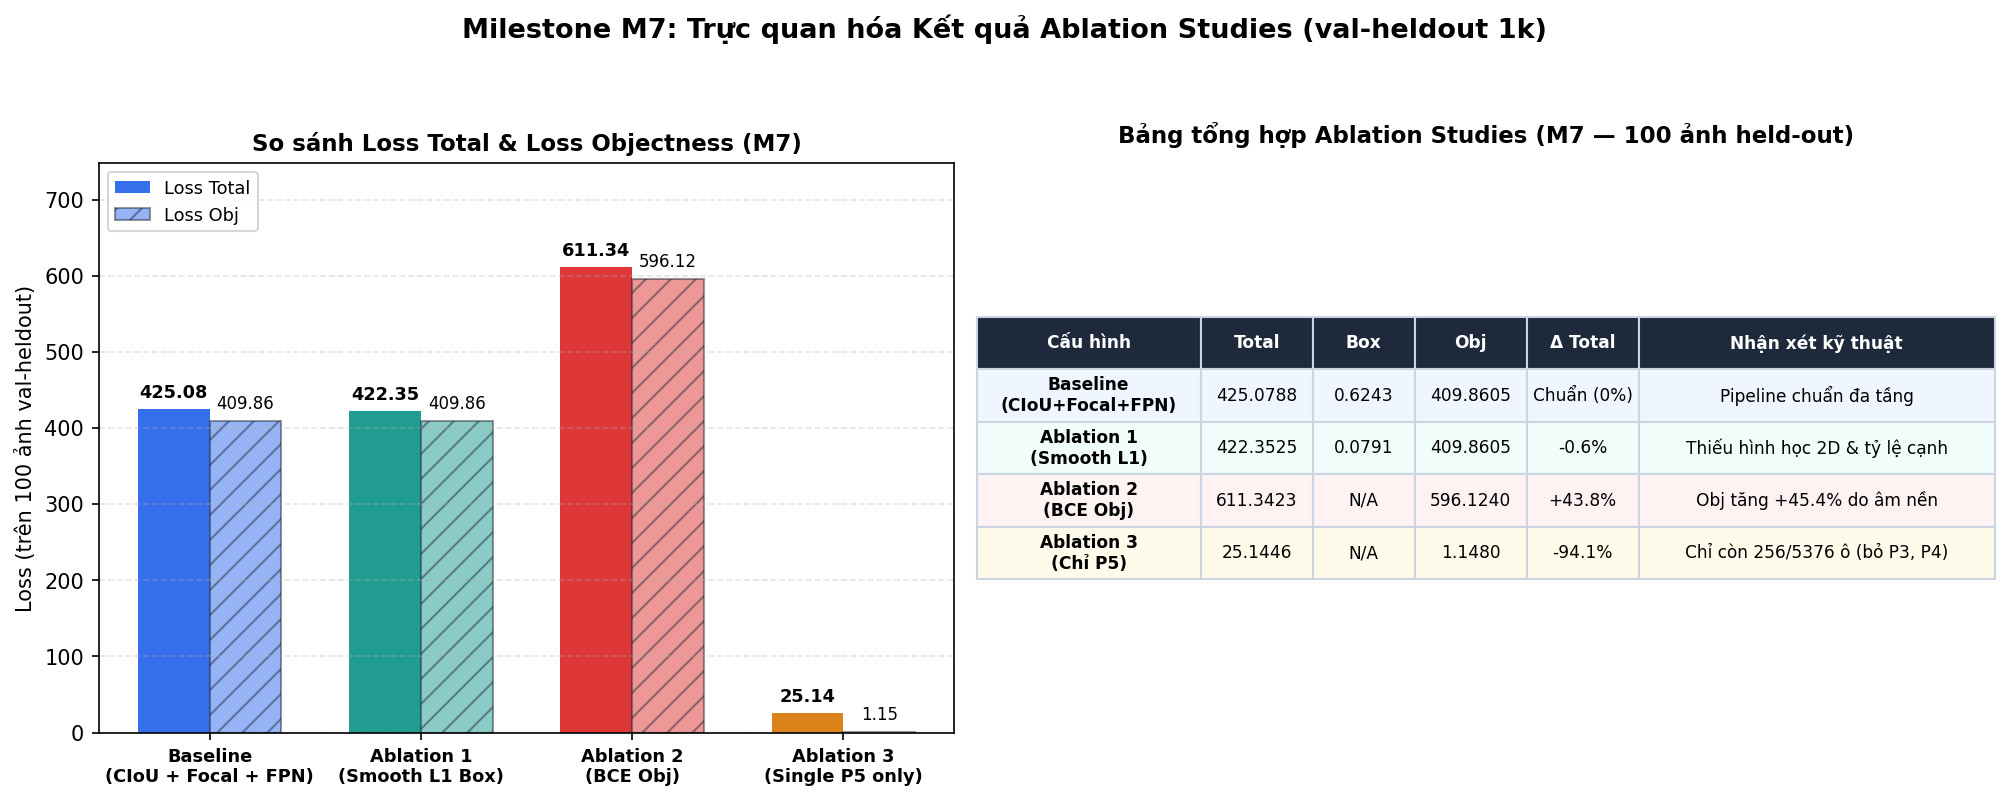

In [5]:
display(IPyImage(filename=str(ROOT / "outputs/visualizations/metrics/m7_ablation_comparison.png")))

## 6. Đánh giá Chính thức `val2017` (M8 — Đã Khóa) & Mức độ Bắt vật tại Epoch 3

- **M8 (`outputs/final_eval.lock`):** Chạy đúng 1 lần trên `val2017` (`200` ảnh / `20.000` predictions, tốc độ **2.61 FPS trên CPU**). Do M8 chạy trước khi model hội tụ ở Epoch 3, `mAP@[.50:.95]` khi đó còn thấp (`0.0000`, `AP_large = 0.0001`).
- **Thống kê khả năng bắt vật tại Epoch 3** (trên `1.000` ảnh `val-heldout 1k`, `6.903` vật thể thật):

In [6]:
preds_ep3 = load_json("outputs/evaluation_results/predictions_heldout_epoch_3.json")
gt_heldout = load_json("data/coco/val_heldout1k.json")
n_imgs = len(gt_heldout["images"])

cov_rows = []
for th in [0.05, 0.15, 0.25, 0.30, 0.40]:
    kept = [p for p in preds_ep3 if p["score"] >= th]
    det_imgs = len(set(p["image_id"] for p in kept))
    cov_rows.append({
        "Ngưỡng confidence": f">= {th:.2f}",
        "Số ảnh có box bắt được": f"{det_imgs} / {n_imgs} ({det_imgs/n_imgs*100:.1f}%)",
        "Tổng số box dự đoán": len(kept),
        "TB box / ảnh": round(len(kept) / n_imgs, 2),
    })

display(pd.DataFrame(cov_rows))

,Ngưỡng confidence,Số ảnh có box bắt được,Tổng số box dự đoán,TB box / ảnh
0,>= 0.05,997 / 1000 (99.7%),75209,75.21
1,>= 0.15,977 / 1000 (97.7%),19144,19.14
2,>= 0.25,843 / 1000 (84.3%),4824,4.82
3,>= 0.30,705 / 1000 (70.5%),2500,2.50
4,>= 0.40,374 / 1000 (37.4%),716,0.72


## 7. Hình ảnh Thực tế Model đã Demo & Bắt được Vật thể

Dưới đây là:
1. **Ảnh demo từ CLI `src.demo`** (`000000000139_detected.jpg`, lưu ở mốc đầu M9).
2. **6 ảnh thực tế model Epoch 3 bắt được trên `val-heldout 1k`** (lọc gọn ở ngưỡng `conf >= 0.22`, khung **xanh lá** = Ground Truth, khung **đỏ** = Model dự đoán kèm tên lớp & điểm tin cậy).

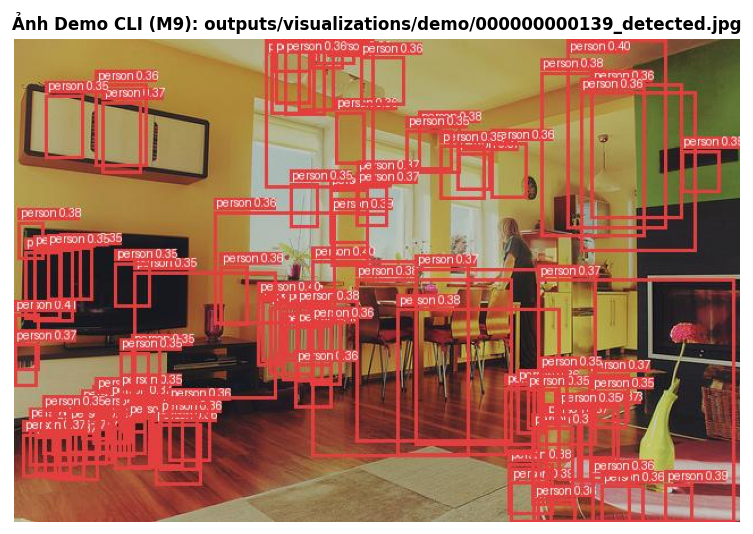

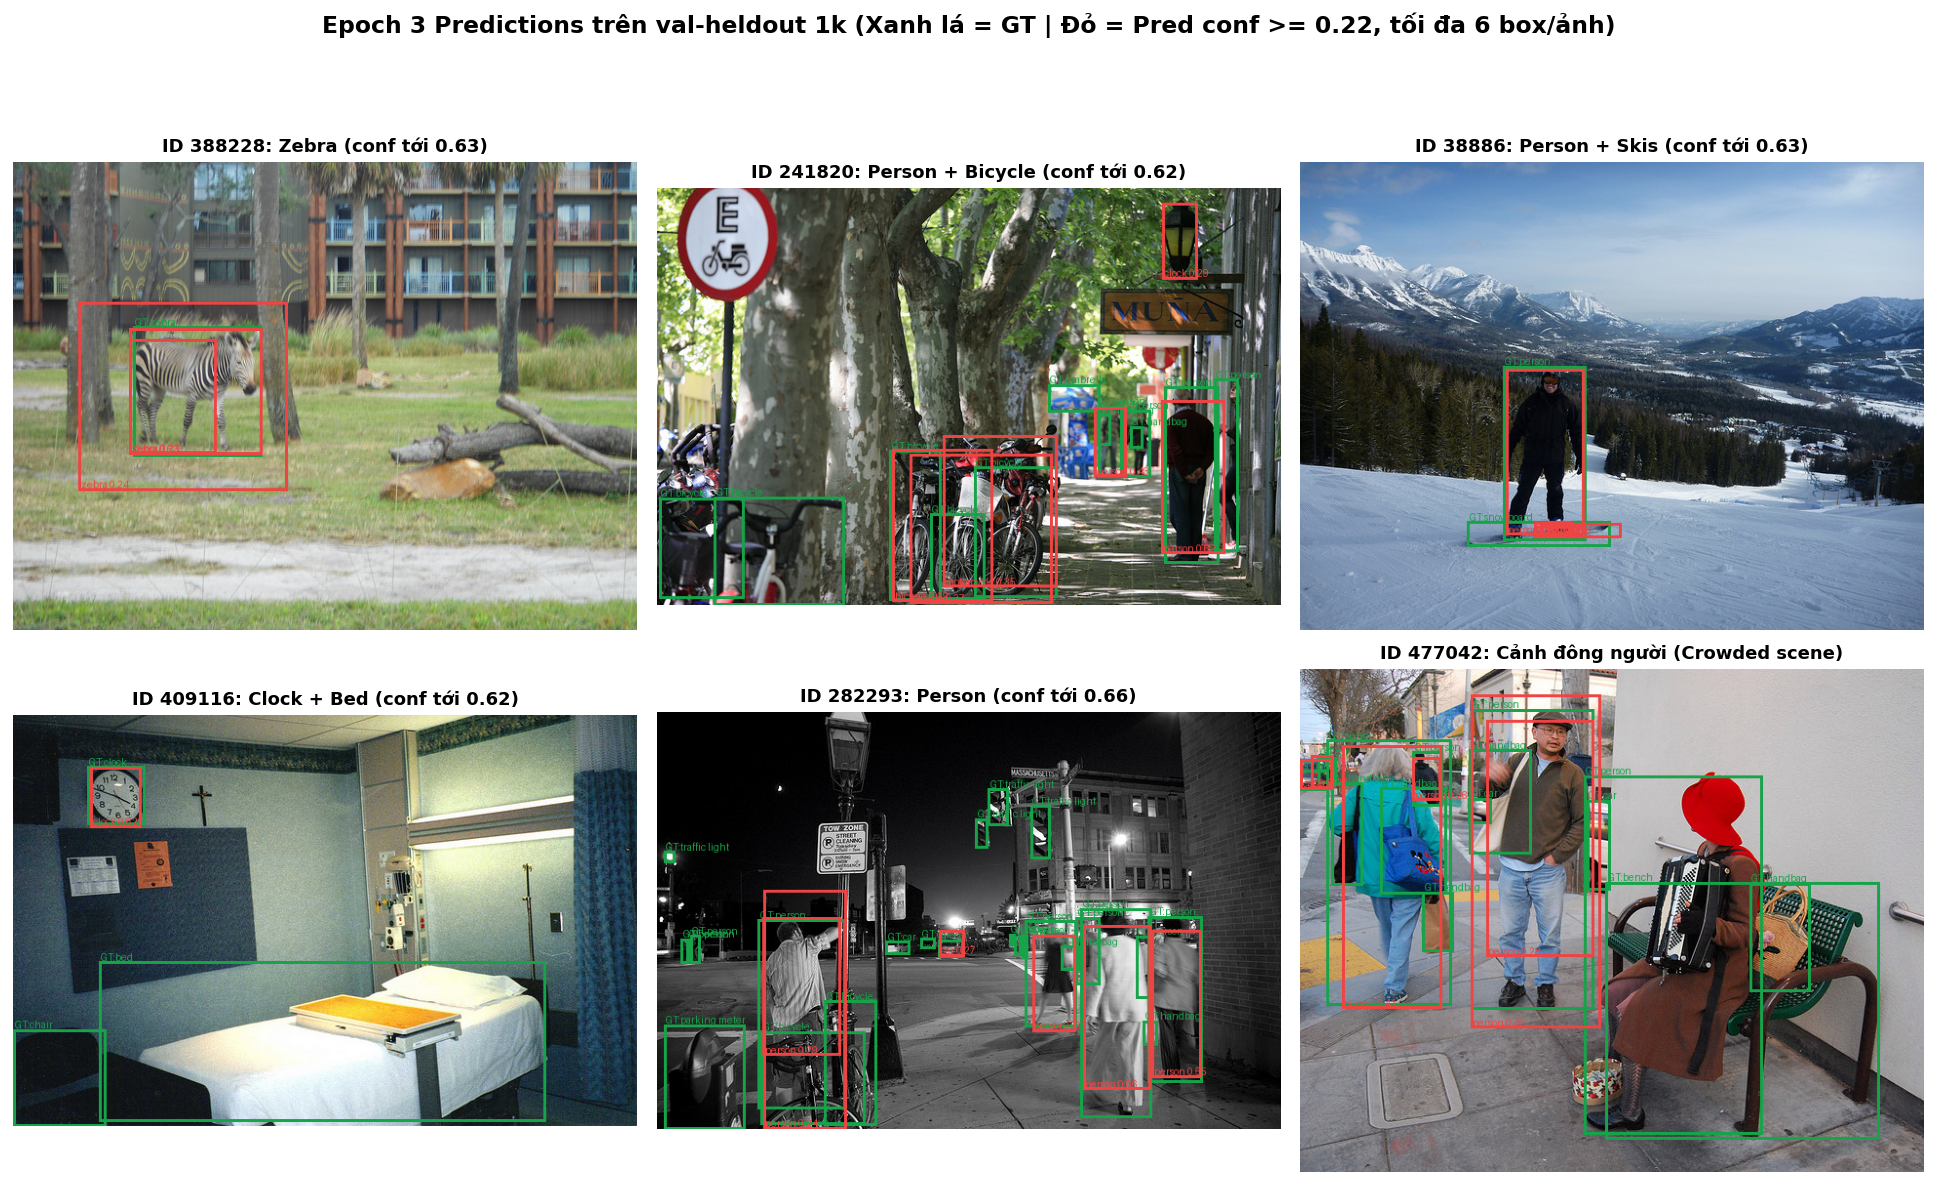

In [7]:
demo_img_path = ROOT / "outputs/visualizations/demo/000000000139_detected.jpg"
if demo_img_path.exists():
    fig_d, ax_d = plt.subplots(figsize=(6.5, 4.5), dpi=120)
    ax_d.imshow(Image.open(demo_img_path))
    ax_d.set_title("Ảnh Demo CLI (M9): outputs/visualizations/demo/000000000139_detected.jpg", fontsize=10, fontweight="bold")
    ax_d.axis("off")
    plt.tight_layout()
    plt.show()

# Vẽ lưới 6 ảnh tiêu biểu từ predictions_heldout_epoch_3.json (GT xanh lá vs Pred đỏ, conf >= 0.22)
imgs_info = {im["id"]: im for im in gt_heldout["images"]}
cats_map = {c["id"]: c["name"] for c in gt_heldout["categories"]}
gt_by_img = defaultdict(list)
for ann in gt_heldout["annotations"]:
    if ann.get("iscrowd", 0) == 0:
        gt_by_img[ann["image_id"]].append(ann)

pred_by_img = defaultdict(list)
for p in preds_ep3:
    if p["score"] >= 0.22:
        pred_by_img[p["image_id"]].append(p)

showcase_ids = [
    (388228, "Zebra (conf tới 0.63)"),
    (241820, "Person + Bicycle (conf tới 0.62)"),
    (38886,  "Person + Skis (conf tới 0.63)"),
    (409116, "Clock + Bed (conf tới 0.62)"),
    (282293, "Person (conf tới 0.66)"),
    (477042, "Cảnh đông người (Crowded scene)"),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9.5), dpi=130)
for ax, (img_id, title) in zip(axes.flat, showcase_ids):
    im_path = ROOT / "data/coco/train2017" / imgs_info[img_id]["file_name"]
    canvas = Image.open(im_path).convert("RGB")
    draw = ImageDraw.Draw(canvas)

    for g in gt_by_img[img_id]:
        x, y, w, h = g["bbox"]
        draw.rectangle([x, y, x + w, y + h], outline="#16A34A", width=3)
        draw.text((x + 2, max(0, y - 11)), f"GT:{cats_map[g['category_id']]}", fill="#16A34A")

    top_preds = sorted(pred_by_img[img_id], key=lambda p: -p["score"])[:6]
    for p in top_preds:
        x, y, w, h = p["bbox"]
        draw.rectangle([x, y, x + w, y + h], outline="#EF4444", width=3)
        draw.text((x + 2, min(canvas.height - 12, y + h - 12)), f"{cats_map[p['category_id']]} {p['score']:.2f}", fill="#EF4444")

    ax.imshow(canvas)
    ax.set_title(f"ID {img_id}: {title}", fontsize=10, fontweight="bold")
    ax.axis("off")

fig.suptitle("Epoch 3 Predictions trên val-heldout 1k (Xanh lá = GT | Đỏ = Pred conf >= 0.22, tối đa 6 box/ảnh)", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## 8. Hạn chế Hiện tại & Hướng Phát triển

### Hạn chế (Limitations)
1. **Tài nguyên CPU-only:** Train mỗi epoch tốn ~4–5 giờ trên CPU nên thực tế giới hạn **5 epochs** (thay vì 20 epochs thiết kế gốc), các box tự tin cao (`conf >= 0.40`) chưa nhiều và vẫn còn box trùng lân cận.
2. **Tập train con 14k ảnh (~12% COCO):** Các lớp ít xuất hiện khó đạt AP cao.
3. **Vật thể rất nhỏ (`< 32×32 px`):** Đầu vào `512×512` làm `AP_small` (`0.0506` ở Ep 3) còn thấp hơn đáng kể so với `AP_large` (`0.1536`).

### Hướng Cải tiến (Future Work)
1. **Hoàn tất Epoch 4–5** (unfreeze ResNet-50 layers 2–4) và chuyển lên **GPU với đủ 118k ảnh `train2017`** + tăng cường dữ liệu Mosaic / MixUp.
2. **Nâng cấp Assigner** từ Static 3-ô sang **SimOTA / TAL** và thêm tầng **$P_2$ (stride 4)** để bắt vật nhỏ tốt hơn.
3. **Xuất ONNX / TensorRT** nhằm tăng tốc suy luận từ `2.61 FPS` (CPU) lên mức thời gian thực (`>= 30 FPS` trên GPU).